In [1]:
import torch
import os
import torchvision
from torchvision.transforms import v2
from torchvision import datasets, transforms
from torchvision import datasets
from pathlib import Path
from torch.utils.data import WeightedRandomSampler
from torch.utils.data import DataLoader
import torchvision.models as models
from tqdm.auto import tqdm
import torchinfo
from timeit import default_timer as timer
from torchinfo import summary
from typing import Dict, List
import matplotlib.pyplot as plt
import mlxtend
import torchmetrics
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix
import requests
from collections import Counter
import torch.nn as nn
from sklearn.metrics import f1_score, classification_report
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale = (0.7,1), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.TrivialAugmentWide(num_magnitude_bins=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [4]:
%cd ..

c:\Users\Fidel S\OneDrive\Desktop\OneAlpha\OneAlpha


In [5]:
test_dir = Path("Data/new_data/test")
train_dir = Path("Data/new_data/train")
val_dir = Path("Data/new_data/val")

In [6]:
train_data = datasets.ImageFolder(root=train_dir, transform=train_transform, target_transform=None)
test_data = datasets.ImageFolder(root=test_dir, transform=val_test_transform)
val_data = datasets.ImageFolder(root=val_dir, transform=val_test_transform)

In [7]:
len(train_data.classes)

75

In [8]:
target = [label for _, label in train_data.samples]
target

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


In [9]:
class_count = Counter(target)
class_count

Counter({51: 5518,
         41: 4125,
         35: 4083,
         28: 4010,
         29: 3993,
         27: 3966,
         55: 3096,
         66: 3028,
         6: 2940,
         65: 2837,
         73: 2804,
         49: 2369,
         21: 2272,
         2: 2207,
         38: 2123,
         13: 2109,
         31: 2072,
         10: 2011,
         14: 1781,
         52: 1743,
         22: 1737,
         40: 1722,
         11: 1566,
         69: 1252,
         72: 1142,
         23: 1087,
         57: 1037,
         19: 876,
         17: 826,
         62: 805,
         0: 704,
         8: 700,
         9: 700,
         12: 700,
         16: 700,
         18: 700,
         20: 700,
         24: 700,
         25: 700,
         32: 700,
         33: 700,
         39: 700,
         47: 700,
         50: 700,
         61: 700,
         64: 700,
         70: 700,
         71: 700,
         74: 700,
         54: 699,
         36: 672,
         63: 606,
         53: 548,
         60: 499,
      

In [10]:
class_weights = {cls: 1/count for cls, count in class_count.items()}
class_weights

{0: 0.0014204545454545455,
 1: 0.004098360655737705,
 2: 0.00045310376076121433,
 3: 0.00847457627118644,
 4: 0.002967359050445104,
 5: 0.0023923444976076554,
 6: 0.0003401360544217687,
 7: 0.006329113924050633,
 8: 0.0014285714285714286,
 9: 0.0014285714285714286,
 10: 0.0004972650422675286,
 11: 0.0006385696040868455,
 12: 0.0014285714285714286,
 13: 0.000474158368895211,
 14: 0.0005614823133071309,
 15: 0.007194244604316547,
 16: 0.0014285714285714286,
 17: 0.0012106537530266344,
 18: 0.0014285714285714286,
 19: 0.001141552511415525,
 20: 0.0014285714285714286,
 21: 0.00044014084507042255,
 22: 0.0005757052389176742,
 23: 0.0009199632014719411,
 24: 0.0014285714285714286,
 25: 0.0014285714285714286,
 26: 0.004016064257028112,
 27: 0.0002521432173474534,
 28: 0.00024937655860349125,
 29: 0.00025043826696719256,
 30: 0.0053475935828877,
 31: 0.00048262548262548264,
 32: 0.0014285714285714286,
 33: 0.0014285714285714286,
 34: 0.003861003861003861,
 35: 0.0002449179524859172,
 36: 0.001

In [11]:
sample_weights = [class_weights[label] for label in target]
sample_weights

[0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454545455,
 0.0014204545454

In [12]:
len(sample_weights)

93354

In [13]:
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

In [14]:
BATCH_SIZE = 8

train_dataloader = DataLoader(
    dataset=train_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    sampler=sampler,
    num_workers=0,
    pin_memory=True
)
test_dataloader = DataLoader(
    dataset=test_data,
    batch_size=BATCH_SIZE,
    num_workers=0,
    shuffle=False,
    pin_memory=True
)
val_dataloader = DataLoader(
    dataset=val_data,
    batch_size=BATCH_SIZE,
    num_workers=0,
    shuffle=False,
    pin_memory=True
)

In [15]:
model_1 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for param in model_1.parameters():
    param.requires_grad = False

In [16]:
model_1.fc = nn.Linear(model_1.fc.in_features,75)

In [17]:
summary(model=model_1,
        input_size=(1,3,224,224))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 75]                   --
├─Conv2d: 1-1                            [1, 64, 112, 112]         (9,408)
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         (128)
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [1, 256, 56, 56]          --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           (4,096)
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           (128)
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           (36,864)
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           (128)
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]    

In [18]:
def train_step(model: torch.nn.Module,
          loss_fn: torch.nn.Module,
          optimizer: torch.optim.Optimizer,
          X,
          y,
          device=None):
    model.train()

    train_loss = 0

    X,y = X.to(device), y.to(device)

    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss = loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return train_loss

In [19]:
def val_step(model: torch.nn.Module,
         loss_fn: torch.nn.Module,
         X,
         y,
         device=None):
    model.eval()

    val_loss = 0

    with torch.inference_mode():
        X,y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)
        val_loss = loss.item()

    return val_loss, y_pred

In [20]:
%pwd

'c:\\Users\\Fidel S\\OneDrive\\Desktop\\OneAlpha\\OneAlpha'

In [21]:
MODEL_PATH = Path("Models")
MODEL_NAME = "restnet50"
MODEL_SAVE_PATH = MODEL_PATH/MODEL_NAME

In [22]:
len(train_dataloader.dataset)

93354

In [23]:
def train(model: torch.nn.Module,
          train_loss_fn: torch.nn.Module,
          val_loss_fn: torch.nn.Module,
          val_dataloader: torch.utils.data.DataLoader,
          train_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          epochs: int = 5,
          device=None):
    
    results = {
               "train_epoch_loss": [],
               "val_epoch_loss": [],
               "f1_score": []
               }
    
    best_f1 = 0.0
    
    for epoch in tqdm(range(epochs)):

        train_epoch_loss = 0
        val_epoch_loss = 0
        all_preds = []
        all_labels = []

        for batch, (X,y) in enumerate(train_dataloader):

            train_loss = train_step(model=model,
                                               loss_fn=train_loss_fn,
                                               optimizer=optimizer,
                                               X=X,
                                               y=y,
                                               device=device)
            train_epoch_loss += train_loss*X.size(0)
        
        for batch, (X,y) in enumerate(val_dataloader):

            val_loss, y_pred = val_step(model=model,
                                            loss_fn=val_loss_fn,
                                            X=X,
                                            y=y,
                                            device=device)
            preds = torch.argmax(y_pred, dim=1)
            val_epoch_loss += val_loss*X.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

        train_epoch_loss = train_epoch_loss/len(train_dataloader.dataset)
        val_epoch_loss = val_epoch_loss/len(val_dataloader.dataset)
        macro_f1 = f1_score(all_labels, all_preds, average="macro")

        results["f1_score"].append(macro_f1)
        results["val_epoch_loss"].append(val_epoch_loss)
        results["train_epoch_loss"].append(train_epoch_loss)

        if macro_f1 > best_f1:
            best_f1 = macro_f1 
            torch.save(obj=model.state_dict(), f=MODEL_SAVE_PATH)
        
        print(f"Epoch: {epoch+1} | train_loss: {train_epoch_loss:.4f} | val_loss: {val_epoch_loss:.4f} | F1 score: {macro_f1:.4f} | Best F1: {best_f1:.4f}")

        
    return results

In [30]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [31]:
for param in loaded_model.layer4.parameters():
    param.requires_grad = True

In [32]:
weights = [weight for label, weight in class_weights.items()]
weights

[0.0014204545454545455,
 0.004098360655737705,
 0.00045310376076121433,
 0.00847457627118644,
 0.002967359050445104,
 0.0023923444976076554,
 0.0003401360544217687,
 0.006329113924050633,
 0.0014285714285714286,
 0.0014285714285714286,
 0.0004972650422675286,
 0.0006385696040868455,
 0.0014285714285714286,
 0.000474158368895211,
 0.0005614823133071309,
 0.007194244604316547,
 0.0014285714285714286,
 0.0012106537530266344,
 0.0014285714285714286,
 0.001141552511415525,
 0.0014285714285714286,
 0.00044014084507042255,
 0.0005757052389176742,
 0.0009199632014719411,
 0.0014285714285714286,
 0.0014285714285714286,
 0.004016064257028112,
 0.0002521432173474534,
 0.00024937655860349125,
 0.00025043826696719256,
 0.0053475935828877,
 0.00048262548262548264,
 0.0014285714285714286,
 0.0014285714285714286,
 0.003861003861003861,
 0.0002449179524859172,
 0.001488095238095238,
 0.002028397565922921,
 0.0004710315591144607,
 0.0014285714285714286,
 0.0005807200929152149,
 0.00024242424242424242,
 

In [33]:
EPOCHS = 5

weights_tensor = torch.tensor(weights, dtype=torch.float32).to(device)
train_loss_fn = torch.nn.CrossEntropyLoss(weight=weights_tensor)
val_loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.0001, weight_decay=0.0001)

start_time = timer()

model_1_results = train(
                        train_loss_fn = train_loss_fn,
                        val_loss_fn = val_loss_fn,
                        optimizer=optimizer,
                        train_dataloader=train_dataloader,
                        val_dataloader=val_dataloader,
                        epochs = EPOCHS,
                        device=device,
                        model=loaded_model)

end_time = timer()

print(f"Total training time: {end_time-start_time:.3f} seconds")

 20%|██        | 1/5 [49:30<3:18:03, 2970.95s/it]

Epoch: 1 | train_loss: 0.4447 | val_loss: 0.7153 | F1 score: 0.7830 | Best F1: 0.7830


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
 40%|████      | 2/5 [1:41:30<2:32:55, 3058.57s/it]

Epoch: 2 | train_loss: 0.3163 | val_loss: 0.6572 | F1 score: 0.8008 | Best F1: 0.8008


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
 60%|██████    | 3/5 [2:34:13<1:43:32, 3106.05s/it]

Epoch: 3 | train_loss: 0.2657 | val_loss: 0.6089 | F1 score: 0.8154 | Best F1: 0.8154


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
 80%|████████  | 4/5 [3:21:24<49:57, 2997.45s/it]  

Epoch: 4 | train_loss: 0.2390 | val_loss: 0.5942 | F1 score: 0.8246 | Best F1: 0.8246


c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 5/5 [4:04:43<00:00, 2936.60s/it]

Epoch: 5 | train_loss: 0.2244 | val_loss: 0.5730 | F1 score: 0.8240 | Best F1: 0.8246
Total training time: 14683.021 seconds


In [34]:
loaded_model = model_1
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [35]:
def plot_loss_curves(results: Dict[str, List[float]]):
    train_loss = results["train_epoch_loss"]
    val_loss = results["val_epoch_loss"]

    val_batch = range(len(results["val_epoch_loss"]))
    train_batch = range(len(results["train_epoch_loss"]))

    plt.figure(figsize=(15,7))

    plt.subplot(1,1,1)
    plt.plot(train_batch, train_loss, label="train_loss")
    plt.plot(val_batch, val_loss, label="val_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

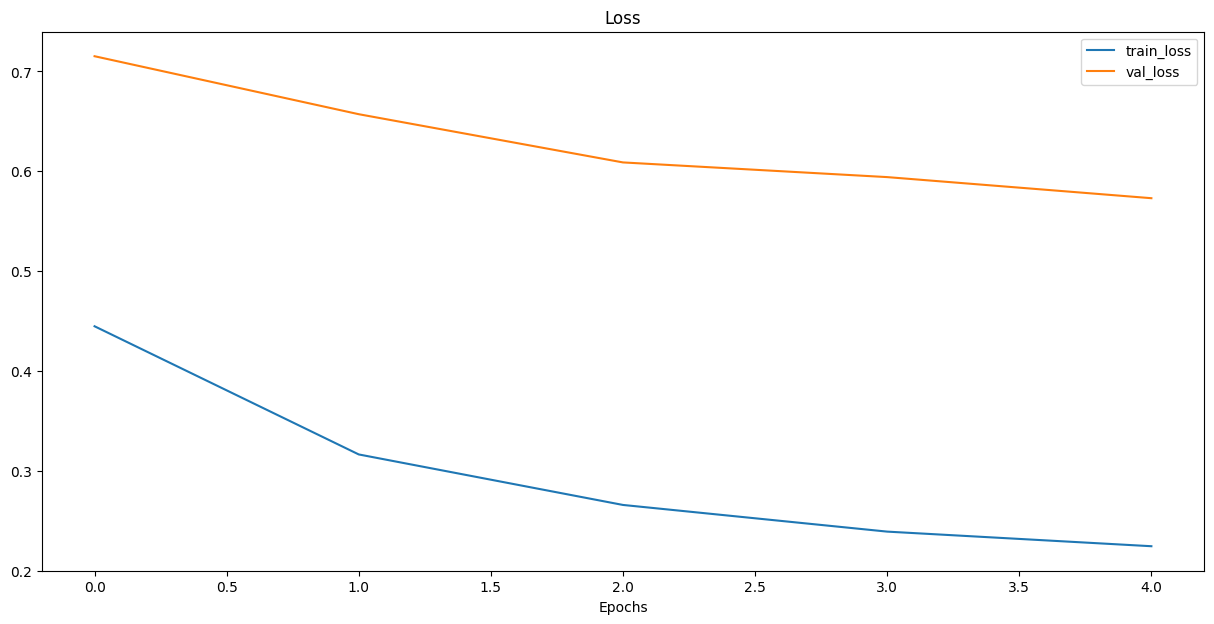

In [36]:
plot_loss_curves(model_1_results)

In [37]:
loaded_model.eval()

y_preds = []
y_pred = 0
all_preds = []
all_labels = []
with torch.inference_mode():
    for X,y in tqdm(test_dataloader):
        X,y = X.to(device), y.to(device)

        y_pred = loaded_model(X)

        y_pred_class = torch.argmax(y_pred, dim=1)

        all_preds.extend(y_pred_class.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
report = classification_report(all_labels, all_preds, digits=3)

  2%|▏         | 53/2506 [00:07<05:31,  7.39it/s]c:\Users\Fidel S\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
100%|██████████| 2506/2506 [05:31<00:00,  7.57it/s]


In [38]:
print(report)

              precision    recall  f1-score   support

           0      0.484     0.816     0.608       152
           1      0.224     0.811     0.351        53
           2      0.872     0.895     0.883       474
           3      1.000     0.962     0.980        26
           4      0.807     0.973     0.882        73
           5      0.528     0.944     0.677        90
           6      0.949     0.741     0.832       630
           7      0.923     0.706     0.800        34
           8      0.802     0.893     0.845       150
           9      0.830     0.813     0.822       150
          10      0.795     0.810     0.802       431
          11      0.857     0.893     0.875       336
          12      0.753     0.773     0.763       150
          13      0.678     0.660     0.669       453
          14      0.870     0.908     0.889       382
          15      0.651     0.903     0.757        31
          16      0.835     0.880     0.857       150
          17      0.888    

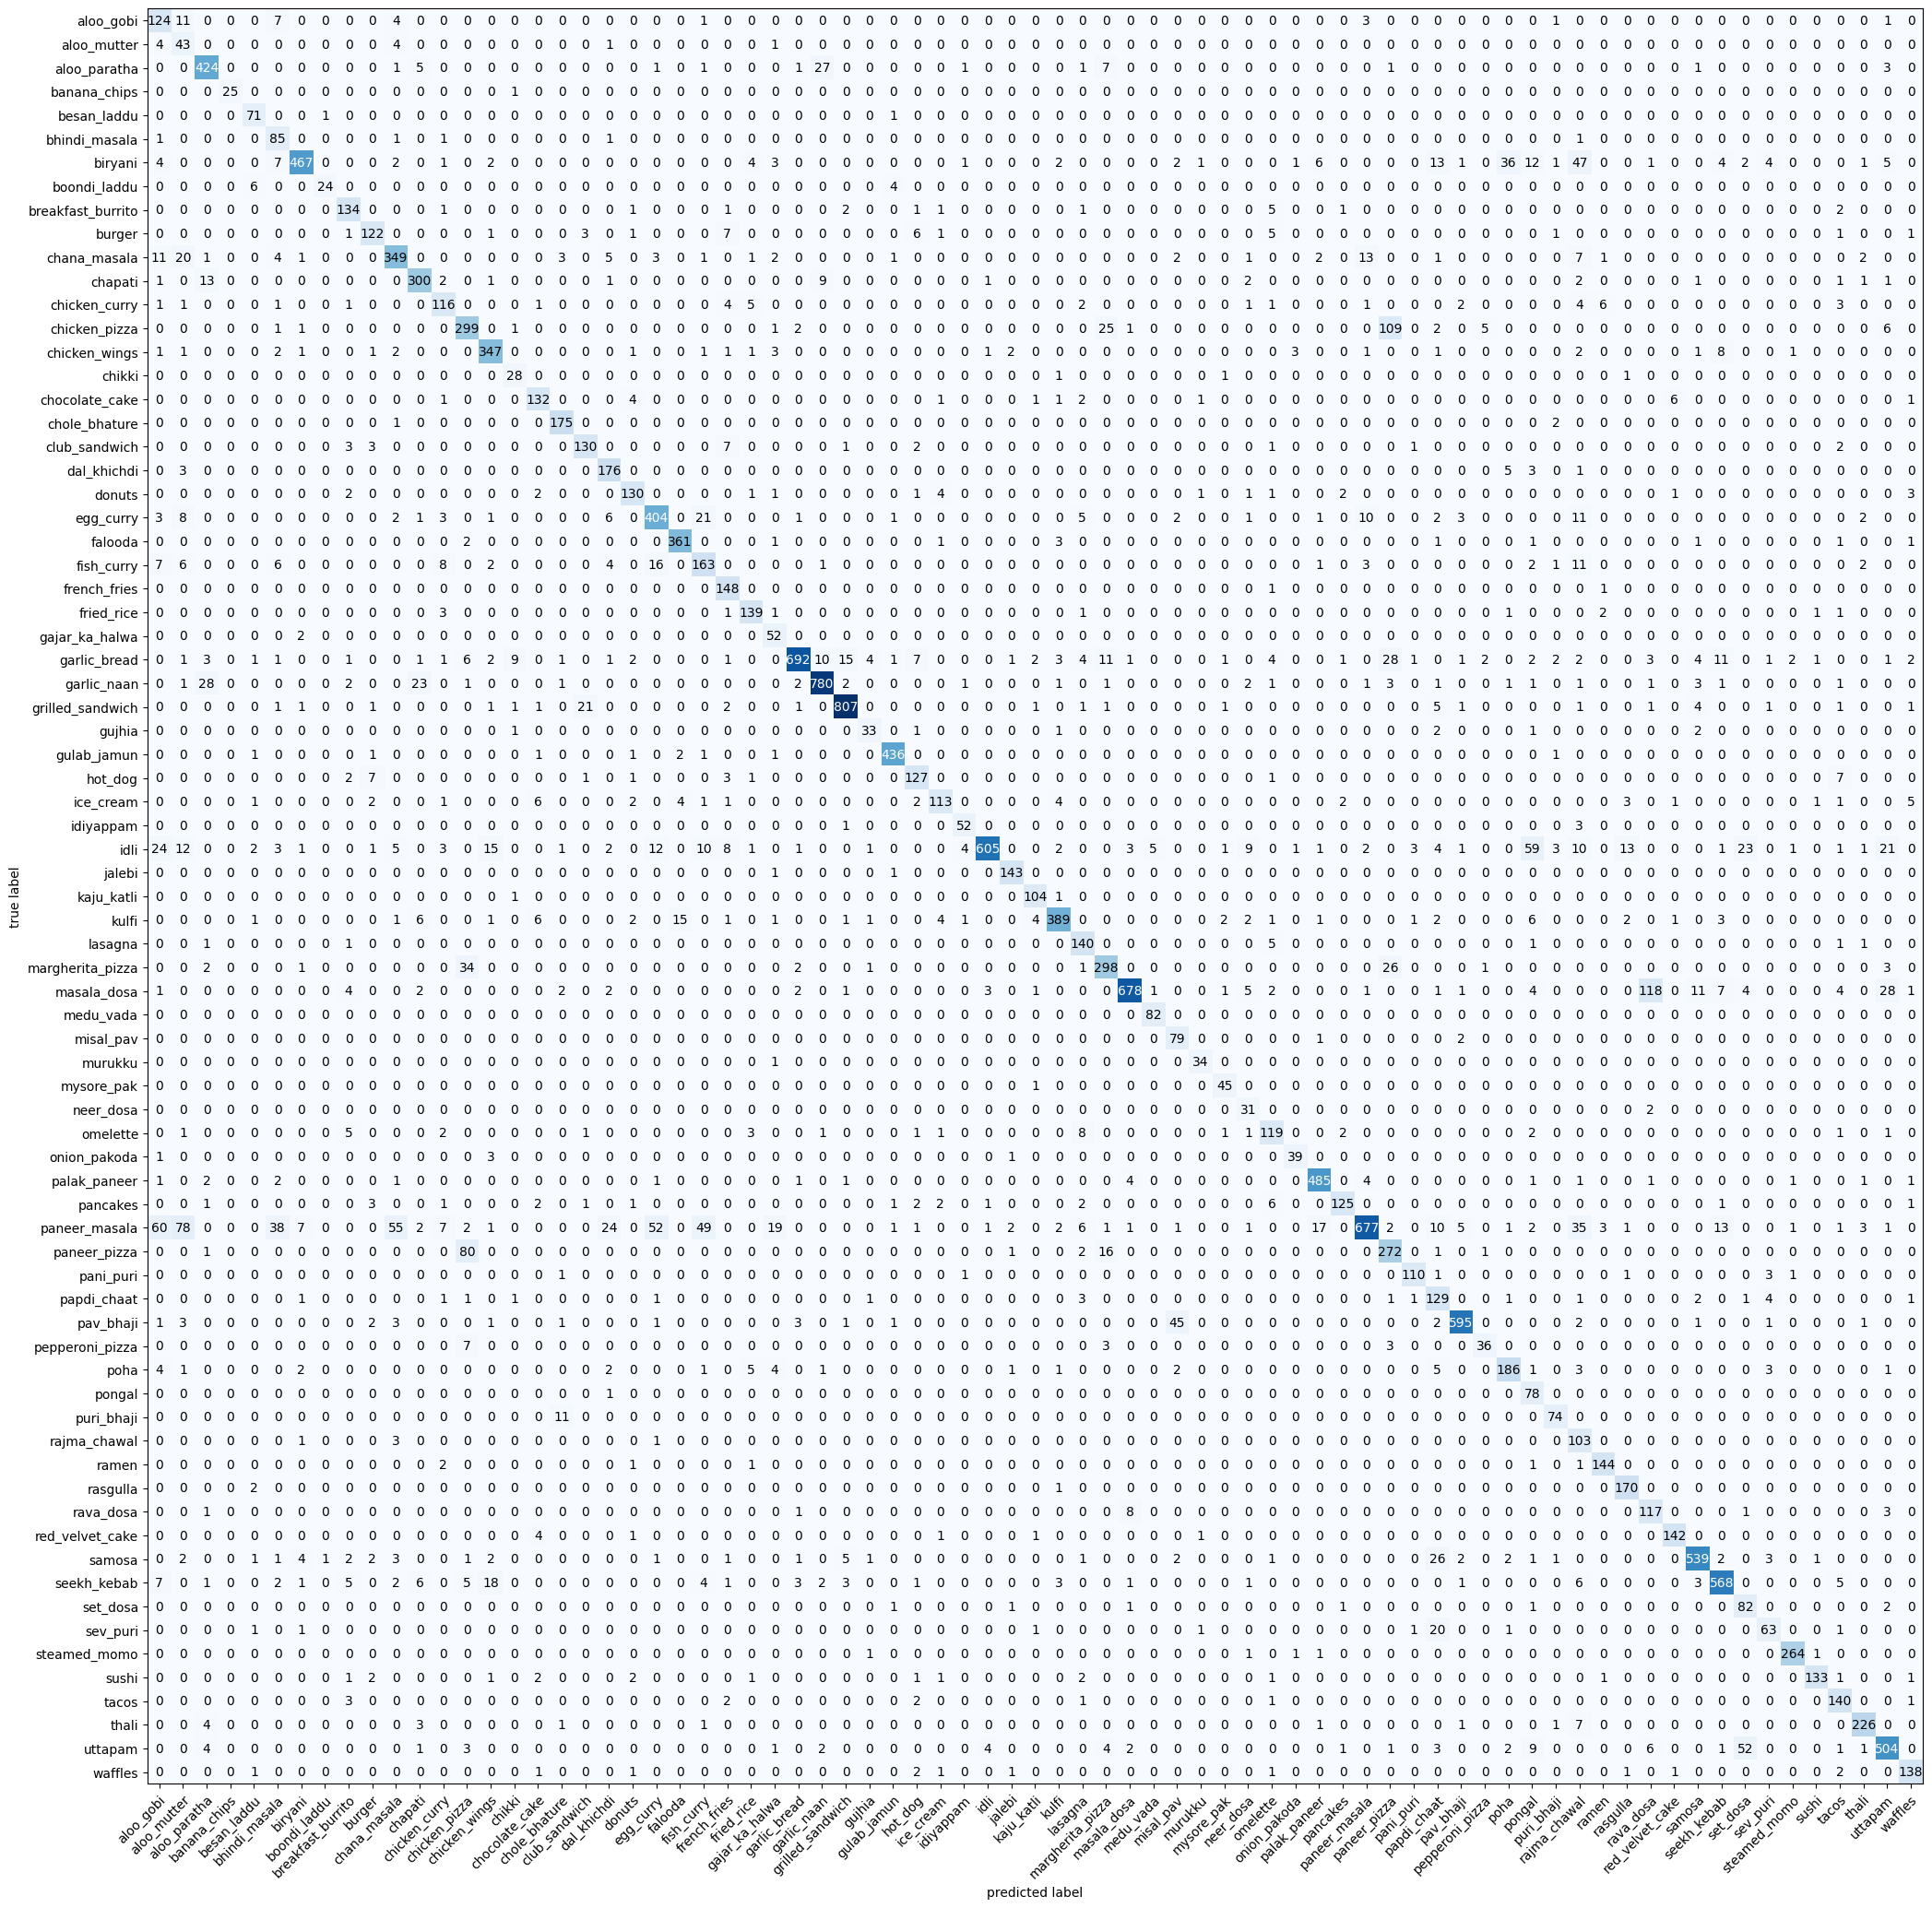

In [39]:
class_names = train_data.classes
all_preds_tensor = torch.tensor(all_preds)
all_labels_tensor = torch.tensor(all_labels)
confmat = ConfusionMatrix(num_classes=75, task="multiclass")
confmat_tensor = confmat(preds=all_preds_tensor, target=all_labels_tensor)
fig, ax = plot_confusion_matrix(conf_mat=confmat_tensor.numpy(),
                                class_names=class_names,
                                figsize=(25,25))

In [51]:
test_data.targets

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,


In [40]:
custom_image_path = Path("custom samples/chips_1.jpg")

custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)/255
print(f"custom_image_unit8.shape: {custom_image.shape}")
print(f"custom_image_unit8.dtype: {custom_image.dtype}")

custom_image_unit8.shape: torch.Size([3, 3000, 4000])
custom_image_unit8.dtype: torch.float32


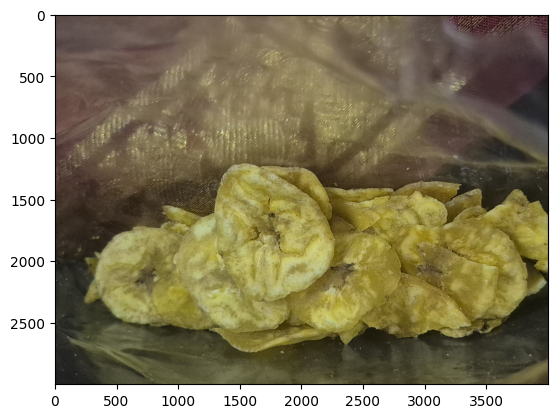

In [41]:
plt.imshow(custom_image.permute(1,2,0))

In [ ]:
custom_transform = transforms.Compose([
    transforms.Resize(size=(224, 224), antialias=True),
    transforms.CenterCrop(224), 
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [43]:
custom_image_transformed = custom_transform(custom_image)
custom_image_transformed.shape

TypeError: pic should be PIL Image or ndarray. Got <class 'torch.Tensor'>